# Practical Exercise 4: Autonomous Trailer as a Knowledge Based Agent

189731 - KARANJA JOY WANGARI

172827 - AYIEKO AUDREY NYATICHI

189807 - AGWATA FELICIA NYABOKE

In Practical Exercise 3 we designed our trailer as a searching agent that finds the best route
from Nairobi to Kisumu using Uniform Cost Search. In this exercise we turn it into a knowledge based agent.

A knowledge based agent has:
- a knowledge base (KB) - the facts and rules it knows about the world
- an inference engine - it uses the rules to decide what to do
- TELL- we tell the agent what its sensors see (percepts)
- ASK- we ask the agent what action it should take

Our knowledge base uses the directed graph, the search tree and the distances from Practical Exercise 3
plus facts about the tanker, the roads and live weather from an API.

## 1. Import libraries
heapq is for the priority queue in UCS. requests is used to get live weather
from the Open-Meteo API.

In [ ]:
import heapq
import math
import requests

## 2. Knowledge Base Part 1 - The Directed Graph (from Exercise 3)
This is the same graph from Practical Exercise 3. Each town points to the towns it connects to and the
distance in km. It is a directed graph so the roads only go one way that is towards Kisumu.

In [ ]:
# Our graph from Exercise 3
graph = {
    'Nairobi': {'Nakuru': 161},
    'Nakuru': {'Kericho': 117, 'Eldoret': 156, 'Kisumu': 178},
    'Kericho': {'Kisumu': 84, 'Kisii': 104},
    'Kisii': {'Kisumu': 136},
    'Eldoret': {'Kisumu': 138, 'Kakamega': 106},
    'Kakamega': {'Kisumu': 81},
    'Kisumu': {}
}

for town in graph:
    print(town, "->", graph[town])

Nairobi -> {'Nakuru': 161}
Nakuru -> {'Kericho': 117, 'Eldoret': 156, 'Kisumu': 178}
Kericho -> {'Kisumu': 84, 'Kisii': 104}
Kisii -> {'Kisumu': 136}
Eldoret -> {'Kisumu': 138, 'Kakamega': 106}
Kakamega -> {'Kisumu': 81}
Kisumu -> {}


## 3. Knowledge Base Part 2 - Distance Measures
From Exercise 3 the path cost is the road distance in km. We also add the straight line distance
between towns which is calculated from GPS coordinates using the Haversine formula. This tells the agent how far
it is from Kisumu as the crow flies at any town.

In [ ]:
# GPS location of each town (latitude, longitude)
town_location = {
    'Nairobi': (-1.29, 36.82),
    'Nakuru': (-0.30, 36.07),
    'Kericho': (-0.37, 35.28),
    'Kisii': (-0.68, 34.77),
    'Eldoret': (0.51, 35.27),
    'Kakamega': (0.28, 34.75),
    'Kisumu': (-0.09, 34.77)
}

def straight_line_distance(town1, town2):

    lat1, lon1 = town_location[town1]
    lat2, lon2 = town_location[town2]
    R = 6371
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1-a))
    return round(R * c)

def path_cost(path):

    total = 0
    for i in range(len(path) - 1):
        total = total + graph[path[i]][path[i+1]]
    return total

for town in town_location:
    print(town, "is", straight_line_distance(town, 'Kisumu'), "km from Kisumu in a straight line")

Nairobi is 264 km from Kisumu in a straight line
Nakuru is 146 km from Kisumu in a straight line
Kericho is 65 km from Kisumu in a straight line
Kisii is 66 km from Kisumu in a straight line
Eldoret is 87 km from Kisumu in a straight line
Kakamega is 41 km from Kisumu in a straight line
Kisumu is 0 km from Kisumu in a straight line


## 4. Knowledge Base Part 3 - Facts about the tanker and the roads
These are the facts the agent knows before the trip. They come from our PEAS design in Exercise 3
(fuel tanker, fuel depots, control office, sensors).

In [ ]:
tanker_facts = {
    "cargo": "petrol",
    "max_load_litres": 36000,
    "max_speed_kmh": 80,
    "diesel_tank_litres": 400,
    "diesel_per_km": 0.45,
    "min_tyre_pressure": 100
}

# extra facts about some roads
road_facts = {
    ('Nairobi', 'Nakuru'): {"speed_limit": 80, "weighbridge": True},
    ('Nakuru', 'Kisumu'): {"speed_limit": 80, "weighbridge": False},
    ('Nakuru', 'Kericho'): {"speed_limit": 60, "weighbridge": False},
    ('Nakuru', 'Eldoret'): {"speed_limit": 70, "weighbridge": True},
    ('Kericho', 'Kisumu'): {"speed_limit": 60, "weighbridge": False},
}

# towns where the truck can refuel its own diesel tank
fuel_stations = ['Nairobi', 'Nakuru', 'Kericho', 'Eldoret', 'Kisumu']

# fuel depots (where the tanker loads and offloads petrol)
fuel_depots = ['Nairobi', 'Nakuru', 'Eldoret', 'Kisumu']

print("Tanker facts:", tanker_facts)
print("Fuel stations:", fuel_stations)
print("Fuel depots:", fuel_depots)

Tanker facts: {'cargo': 'petrol', 'max_load_litres': 36000, 'max_speed_kmh': 80, 'diesel_tank_litres': 400, 'diesel_per_km': 0.45, 'min_tyre_pressure': 100}
Fuel stations: ['Nairobi', 'Nakuru', 'Kericho', 'Eldoret', 'Kisumu']
Fuel depots: ['Nairobi', 'Nakuru', 'Eldoret', 'Kisumu']


## 5. Knowledge Base Part 4 - Rules
These are the IF - THEN rules the tanker uses on the road. They are based on the sensors and actuators
from our PEAS. The rules are checked in order, so the most dangerous situations such as leaks, fire and people come first.

In [ ]:
rules = [
    ("R1", lambda p: p["leak"] == True,
           "STOP, close tank shut-off valve, sound alarm and call control office"),
    ("R2", lambda p: p["obstacle"] == "pedestrian",
           "EMERGENCY BRAKE - person on the road"),
    ("R3", lambda p: p["obstacle"] == "vehicle" and p["obstacle_distance"] < 50,
           "BRAKE HARD - vehicle too close"),
    ("R4", lambda p: p["tyre_pressure"] < tanker_facts["min_tyre_pressure"],
           "SLOW DOWN, put on indicators and pull over - low tyre pressure"),
    ("R5", lambda p: p["obstacle"] == "animal",
           "SLOW DOWN and HOOT - animal on the road"),
    ("R6", lambda p: p["traffic_light"] == "red",
           "STOP at the traffic light"),
    ("R7", lambda p: p["weighbridge"] == True,
           "STOP at the weighbridge"),
    ("R8", lambda p: p["diesel_percent"] < 15,
           "GO TO THE NEAREST FUEL STATION"),
    ("R9", lambda p: p["weather"] == "rain" or p["weather"] == "fog",
           "REDUCE SPEED and turn on lights - bad weather"),
    ("R10", lambda p: p["speed"] > p["speed_limit"],
           "SLOW DOWN - above the speed limit"),
    ("R11", lambda p: p["obstacle"] == "vehicle" and p["obstacle_distance"] >= 50,
           "KEEP A SAFE DISTANCE behind the vehicle"),
    ("R12", lambda p: True,
           "CONTINUE DRIVING"),
]

for r in rules:
    print(r[0], ":", r[2])

R1 : STOP, close tank shut-off valve, sound alarm and call control office
R2 : EMERGENCY BRAKE - person on the road
R3 : BRAKE HARD - vehicle too close
R4 : SLOW DOWN, put on indicators and pull over - low tyre pressure
R5 : SLOW DOWN and HOOT - animal on the road
R6 : STOP at the traffic light
R7 : STOP at the weighbridge
R8 : GO TO THE NEAREST FUEL STATION
R9 : REDUCE SPEED and turn on lights - bad weather
R10 : SLOW DOWN - above the speed limit
R11 : KEEP A SAFE DISTANCE behind the vehicle
R12 : CONTINUE DRIVING


## 6. The Knowledge Based Agent
The agent class has:
- tell() - stores what the sensors see (percept) in the knowledge base
- ask() - goes through the rules (inference) and returns the action to take

In [ ]:
class TankerAgent:
    def __init__(self, name):
        self.name = name
        self.kb = {}
        self.history = []
        self.time = 0

    def tell(self, percept):

        self.kb = percept
        self.history.append(percept)
        self.time = self.time + 1

    def ask(self):

        for name, condition, action in rules:
            if condition(self.kb):
                return name + ": " + action

agent = TankerAgent("Tanker KBA 001")
print("Agent created:", agent.name)

Agent created: Tanker KBA 001


## 7. Planning the Route - Uniform Cost Search (from Exercise 3)
This is our UCS code from Exercise 3. It prints each town it visits, which shows the search tree.

In [ ]:
def uniform_cost_search(start, goal):

    pq = [(0, start, [start])]
    visited = []

    print("Starting UCS from", start, "to", goal, "\n")

    while pq:
        cost, node, path = heapq.heappop(pq)

        print("Visiting:", node, "| Cost:", cost, "| Path:", " -> ".join(path))

        if node == goal:
            print("\nGoal reached!")
            return cost, path

        if node not in visited:
            visited.append(node)

            for neighbor, distance in graph[node].items():
                if neighbor not in visited:
                    new_cost = cost + distance
                    new_path = path + [neighbor]
                    heapq.heappush(pq, (new_cost, neighbor, new_path))

    return float('inf'), []

final_cost, final_path = uniform_cost_search('Nairobi', 'Kisumu')
print("Best Path:", " -> ".join(final_path))
print("Total Cost:", final_cost, "km")

Starting UCS from Nairobi to Kisumu 

Visiting: Nairobi | Cost: 0 | Path: Nairobi
Visiting: Nakuru | Cost: 161 | Path: Nairobi -> Nakuru
Visiting: Kericho | Cost: 278 | Path: Nairobi -> Nakuru -> Kericho
Visiting: Eldoret | Cost: 317 | Path: Nairobi -> Nakuru -> Eldoret
Visiting: Kisumu | Cost: 339 | Path: Nairobi -> Nakuru -> Kisumu

Goal reached!
Best Path: Nairobi -> Nakuru -> Kisumu
Total Cost: 339 km


## 8. All possible routes (Search Tree)
The agent can also list every route from the start to the goal, like the table in Exercise 3.
This is useful if the best road is blocked and the agent needs a backup route.

In [ ]:
def all_routes(start, goal, path=None):
    if path is None:
        path = [start]
    if start == goal:
        return [path]
    routes = []
    for next_town in graph[start]:
        if next_town not in path:
            routes = routes + all_routes(next_town, goal, path + [next_town])
    return routes

routes = all_routes('Nairobi', 'Kisumu')
routes.sort(key=path_cost)

for r in routes:
    print(" - ".join(r), "=", path_cost(r), "km")

Nairobi - Nakuru - Kisumu = 339 km
Nairobi - Nakuru - Kericho - Kisumu = 362 km
Nairobi - Nakuru - Eldoret - Kisumu = 455 km
Nairobi - Nakuru - Eldoret - Kakamega - Kisumu = 504 km
Nairobi - Nakuru - Kericho - Kisii - Kisumu = 518 km


## 9. Live knowledge from an API (weather)
We use the Open-Meteo API to get the current weather in a town and add it to the knowledge base.
If there is no internet the agent assumes the weather is clear.

In [ ]:
def get_weather(town):
    lat, lon = town_location[town]
    url = "https://api.open-meteo.com/v1/forecast?latitude=" + str(lat) + "&longitude=" + str(lon) + "&current_weather=true"
    try:
        data = requests.get(url, timeout=5).json()
        code = data["current_weather"]["weathercode"]

        if code in [45, 48]:
            return "fog"
        elif code >= 51:
            return "rain"
        else:
            return "clear"
    except:
        print("  (could not reach weather API, assuming clear)")
        return "clear"

for town in final_path:
    print("Weather in", town, ":", get_weather(town))

Weather in Nairobi : rain
Weather in Nakuru : rain
Weather in Kisumu : clear


## 10. Checking the trip before leaving
Before the tanker leaves, the agent checks the load, plans the route with UCS, works out the diesel needed
and warns about weighbridges on the way.

In [ ]:
def check_trip(start, goal, load):
    print("Checking trip from", start, "to", goal, "carrying", load, "litres of", tanker_facts["cargo"])

    if start not in graph or goal not in graph:
        print("Sorry, I don't know that town.")
        return None

    if load > tanker_facts["max_load_litres"]:
        print("Cannot go: the tank can only carry", tanker_facts["max_load_litres"], "litres.")
        return None

    cost, route = uniform_cost_search(start, goal)
    if route == []:
        print("There is no road from", start, "to", goal, "in my map.")
        return None

    diesel = round(cost * tanker_facts["diesel_per_km"])
    hours = cost / tanker_facts["max_speed_kmh"]

    print("\nRoute:", " -> ".join(route))
    print("Distance:", cost, "km")
    print("Diesel needed:", diesel, "litres")
    print("Time (approx):", round(hours, 1), "hours")

    if diesel > tanker_facts["diesel_tank_litres"]:
        print("Diesel tank is not enough. Refuel at:", [t for t in route if t in fuel_stations])
    else:
        print("Diesel tank is enough for the trip.")

    for i in range(len(route) - 1):
        road = (route[i], route[i+1])
        if road in road_facts and road_facts[road]["weighbridge"]:
            print("Note: there is a weighbridge between", road[0], "and", road[1])

    if goal not in fuel_depots:
        print("Warning:", goal, "has no fuel depot to offload at.")

    return route

route = check_trip('Nairobi', 'Kisumu', 30000)

Checking trip from Nairobi to Kisumu carrying 30000 litres of petrol
Starting UCS from Nairobi to Kisumu 

Visiting: Nairobi | Cost: 0 | Path: Nairobi
Visiting: Nakuru | Cost: 161 | Path: Nairobi -> Nakuru
Visiting: Kericho | Cost: 278 | Path: Nairobi -> Nakuru -> Kericho
Visiting: Eldoret | Cost: 317 | Path: Nairobi -> Nakuru -> Eldoret
Visiting: Kisumu | Cost: 339 | Path: Nairobi -> Nakuru -> Kisumu

Goal reached!

Route: Nairobi -> Nakuru -> Kisumu
Distance: 339 km
Diesel needed: 153 litres
Time (approx): 4.2 hours
Diesel tank is enough for the trip.
Note: there is a weighbridge between Nairobi and Nakuru


## 11. Simulating the trip
Now the tanker drives the route. On each road the sensors pick up something (percept). We TELL the
agent, then ASK it what to do. Some percepts are made up here so we can test the rules.

In [ ]:
def drive(route):
    # things the sensors pick up on each road
    events = [
        {"obstacle": "animal", "obstacle_distance": 30, "traffic_light": "none", "speed": 70, "tyre_pressure": 110, "leak": False},
        {"obstacle": "vehicle", "obstacle_distance": 20, "traffic_light": "none", "speed": 75, "tyre_pressure": 110, "leak": False},
        {"obstacle": "none", "obstacle_distance": 0, "traffic_light": "none", "speed": 90, "tyre_pressure": 95, "leak": False},
        {"obstacle": "none", "obstacle_distance": 0, "traffic_light": "none", "speed": 60, "tyre_pressure": 110, "leak": True},
        {"obstacle": "pedestrian", "obstacle_distance": 10, "traffic_light": "none", "speed": 50, "tyre_pressure": 110, "leak": False},
    ]

    diesel = 100
    tanker = TankerAgent("Tanker KBA 001")

    for i in range(len(route) - 1):
        town = route[i]
        next_town = route[i+1]
        info = road_facts.get((town, next_town), {"speed_limit": 80, "weighbridge": False})
        weather = get_weather(town)

        print("Driving from", town, "to", next_town, )

        # percept 1: leaving the town
        percept = {"obstacle": "none", "obstacle_distance": 0, "traffic_light": "red", "speed": 0,
                   "tyre_pressure": 110, "leak": False, "weighbridge": False,
                   "diesel_percent": diesel, "weather": weather, "speed_limit": info["speed_limit"]}
        tanker.tell(percept)
        print("Leaving", town, "| weather:", weather, "| diesel:", diesel, "%")
        print("  Action:", tanker.ask())

        # percept 2: weighbridge on this road
        if info["weighbridge"]:
            percept["traffic_light"] = "none"
            percept["speed"] = 30
            percept["weighbridge"] = True
            tanker.tell(percept)
            print("Weighbridge ahead")
            print("  Action:", tanker.ask())

        # percept 3: something happens on the road
        event = events[i % len(events)]
        percept = dict(event)
        percept["weighbridge"] = False
        percept["diesel_percent"] = diesel
        percept["weather"] = weather
        percept["speed_limit"] = info["speed_limit"]
        tanker.tell(percept)
        print("On the road:", event)
        print("  Action:", tanker.ask())

        # use diesel for this road
        used = graph[town][next_town] * tanker_facts["diesel_per_km"] / tanker_facts["diesel_tank_litres"] * 100
        diesel = round(diesel - used)

    print("\nArrived at", route[-1], "- offloading at the fuel depot.")
    print("Total percepts told to the agent:", tanker.time)

drive(route)

Driving from Nairobi to Nakuru
Leaving Nairobi | weather: rain | diesel: 100 %
  Action: R6: STOP at the traffic light
Weighbridge ahead
  Action: R7: STOP at the weighbridge
On the road: {'obstacle': 'animal', 'obstacle_distance': 30, 'traffic_light': 'none', 'speed': 70, 'tyre_pressure': 110, 'leak': False}
  Action: R5: SLOW DOWN and HOOT - animal on the road
Driving from Nakuru to Kisumu
Leaving Nakuru | weather: rain | diesel: 82 %
  Action: R6: STOP at the traffic light
On the road: {'obstacle': 'vehicle', 'obstacle_distance': 20, 'traffic_light': 'none', 'speed': 75, 'tyre_pressure': 110, 'leak': False}
  Action: R3: BRAKE HARD - vehicle too close

Arrived at Kisumu - offloading at the fuel depot.
Total percepts told to the agent: 5


## 12. Testing a longer route
To test more rules we drive the longest route from Exercise 3 which is through Eldoret and Kakamega.

In [ ]:
long_route = ['Nairobi', 'Nakuru', 'Eldoret', 'Kakamega', 'Kisumu']
print("Route:", " -> ".join(long_route), "=", path_cost(long_route), "km")
drive(long_route)

Route: Nairobi -> Nakuru -> Eldoret -> Kakamega -> Kisumu = 504 km
Driving from Nairobi to Nakuru
Leaving Nairobi | weather: rain | diesel: 100 %
  Action: R6: STOP at the traffic light
Weighbridge ahead
  Action: R7: STOP at the weighbridge
On the road: {'obstacle': 'animal', 'obstacle_distance': 30, 'traffic_light': 'none', 'speed': 70, 'tyre_pressure': 110, 'leak': False}
  Action: R5: SLOW DOWN and HOOT - animal on the road
Driving from Nakuru to Eldoret
Leaving Nakuru | weather: rain | diesel: 82 %
  Action: R6: STOP at the traffic light
Weighbridge ahead
  Action: R7: STOP at the weighbridge
On the road: {'obstacle': 'vehicle', 'obstacle_distance': 20, 'traffic_light': 'none', 'speed': 75, 'tyre_pressure': 110, 'leak': False}
  Action: R3: BRAKE HARD - vehicle too close
Driving from Eldoret to Kakamega
Leaving Eldoret | weather: clear | diesel: 64 %
  Action: R6: STOP at the traffic light
On the road: {'obstacle': 'none', 'obstacle_distance': 0, 'traffic_light': 'none', 'speed': 

## 13. Talk to the Agent (User Interaction)
The user types the number of an option and the agent answers using its knowledge base.
The destination is typed on the keyboard (one of the sensors in our PEAS). Type 0 to exit.

In [ ]:
def menu():
    while True:
        print("AUTONOMOUS FUEL TANKER")
        print("1. Plan a trip")
        print("2. Ask what to do in a situation")
        print("3. Show all routes between two towns")
        print("4. Check weather in a town")
        print("5. Show the towns I know")
        print("0. Exit")
        choice = input("Choose: ")

        if choice == "1":
            start = input("Start town: ").strip().title()
            goal = input("Destination town: ").strip().title()
            load = float(input("Load in litres: "))
            route = check_trip(start, goal, load)
            if route and input("Start driving? (y/n): ").lower() == "y":
                drive(route)

        elif choice == "2":
            p = {}
            p["leak"] = input("Leak detected? (y/n): ").lower() == "y"
            p["obstacle"] = input("Obstacle (none/vehicle/pedestrian/animal): ").strip().lower()
            p["obstacle_distance"] = float(input("Distance to obstacle in m (0 if none): "))
            p["traffic_light"] = input("Traffic light (none/red/green): ").strip().lower()
            p["speed"] = float(input("Current speed km/h: "))
            p["speed_limit"] = float(input("Speed limit km/h: "))
            p["tyre_pressure"] = float(input("Tyre pressure (psi): "))
            p["weighbridge"] = input("Weighbridge ahead? (y/n): ").lower() == "y"
            p["diesel_percent"] = float(input("Diesel %: "))
            p["weather"] = input("Weather (clear/rain/fog): ").strip().lower()
            agent.tell(p)
            print("Agent says:", agent.ask())

        elif choice == "3":
            start = input("Start town: ").strip().title()
            goal = input("Destination town: ").strip().title()
            if start in graph and goal in graph:
                found = all_routes(start, goal)
                found.sort(key=path_cost)
                if found == []:
                    print("No route found.")
                for r in found:
                    print(" - ".join(r), "=", path_cost(r), "km")
            else:
                print("I don't know that town.")

        elif choice == "4":
            town = input("Town: ").strip().title()
            if town in town_location:
                print("Weather in", town, "is", get_weather(town))
            else:
                print("I don't know that town.")

        elif choice == "5":
            print("Towns:", list(graph.keys()))

        elif choice == "0":
            print("Goodbye!")
            break
        else:
            print("Wrong choice, try again.")

menu()

AUTONOMOUS FUEL TANKER
1. Plan a trip
2. Ask what to do in a situation
3. Show all routes between two towns
4. Check weather in a town
5. Show the towns I know
0. Exit
Choose: 1
Start town: Nairobi
Destination town: Kisumu
Load in litres: 30000
Checking trip from Nairobi to Kisumu carrying 30000.0 litres of petrol
Starting UCS from Nairobi to Kisumu 

Visiting: Nairobi | Cost: 0 | Path: Nairobi
Visiting: Nakuru | Cost: 161 | Path: Nairobi -> Nakuru
Visiting: Kericho | Cost: 278 | Path: Nairobi -> Nakuru -> Kericho
Visiting: Eldoret | Cost: 317 | Path: Nairobi -> Nakuru -> Eldoret
Visiting: Kisumu | Cost: 339 | Path: Nairobi -> Nakuru -> Kisumu

Goal reached!

Route: Nairobi -> Nakuru -> Kisumu
Distance: 339 km
Diesel needed: 153 litres
Time (approx): 4.2 hours
Diesel tank is enough for the trip.
Note: there is a weighbridge between Nairobi and Nakuru
Start driving? (y/n): y
Driving from Nairobi to Nakuru
Leaving Nairobi | weather: rain | diesel: 100 %
  Action: R6: STOP at the traffic 

## 14. Conclusion
- We turned the searching agent from Exercise 3 into a knowledge based agent.
- The knowledge base has facts (the directed graph, road distances, straight line distances, tanker details,
  fuel stations, fuel depots, road facts) and IF-THEN rules based on our PEAS sensors and actuators.
- The agent uses TELL to take in percepts and ASK to get the right action from the rules.
- It still uses Uniform Cost Search to find the best route: Nairobi -> Nakuru -> Kisumu (339 km).
- It can list all routes from the search tree as backups if a road is blocked.
- The Open-Meteo API adds live weather to the knowledge base.
- Improvements: add a traffic API, add more towns and let the control office send new rules to the agent.

## 15. Evidence of Group Work


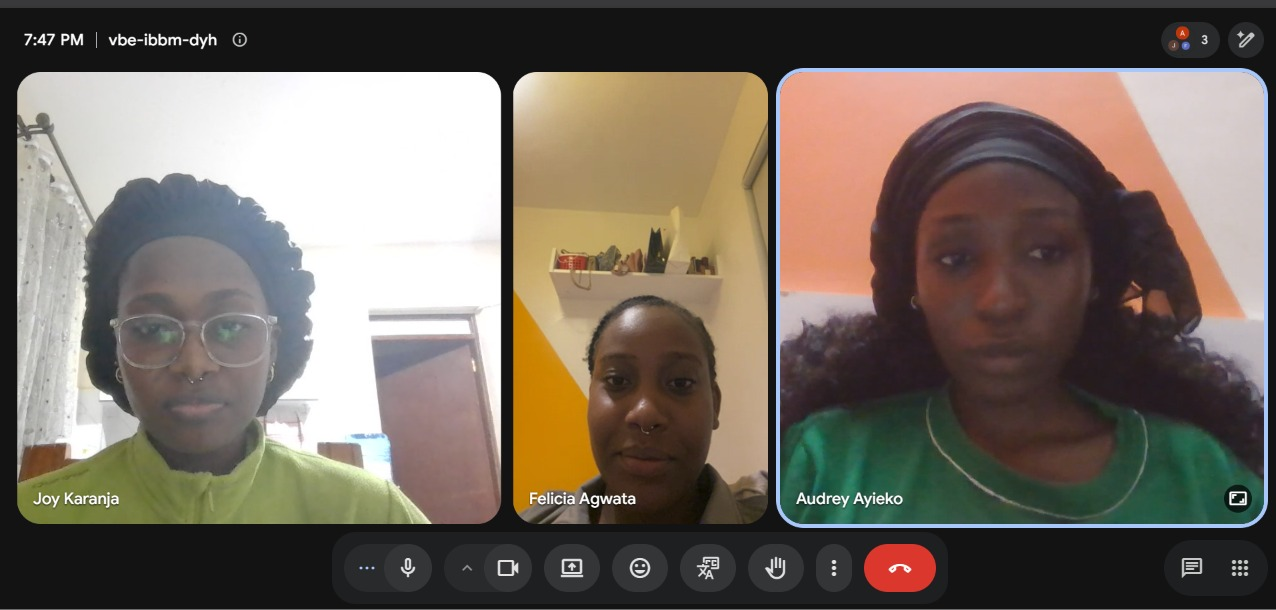
